# ViT · 03-1: Der shapiq-Explainer für Vorhersage und Unsicherheit

- **Voraussetzung:** [03-0](keith_03-0_vit-probly.ipynb) ist ausgeführt (Merkmale und Köpfe sind gespeichert).
- **Ziel:** Schritt 3 und 4 des Pakets: Ein **shapiq-Explainer** erklärt für ein Bild die Vorhersage **und** ihre
  Unsicherheit, getrennt in Rauschen (AU) und fehlendes Wissen (EU), und zeigt beides nebeneinander.

### Was ist ein shapiq-Explainer?

In shapiq ist jeder Explainer eine Unterklasse von `shapiq.Explainer`. Er implementiert `explain_function(x)`:
Für einen Datenpunkt `x` baut er ein **Spiel** und berechnet daraus mit shapiq Shapley-Werte oder Interaktionen.
Unser `UncertaintyExplainer` macht das für Bilder und probly-Modelle:

1. **Spieler** sind 16 SLIC-Superpixel des Bildes (wie bei Tom).
2. Eine **Koalition** S ist eine Menge sichtbarer Superpixel. Die Tokens der anderen werden im Transformer
   ausgeblendet (kein Übermalen).
3. Der **Wert** v(S) ist eine von vier Größen des probly-Modells auf diesem teilweise sichtbaren Bild:
   **P** (Wahrscheinlichkeit der vorhergesagten Klasse), **TU**, **AU** oder **EU**.
4. shapiq wertet **1000 Koalitionen** aus (Budget wie bei Tom) und berechnet daraus zweierlei:
   - **Shapley-Werte** (ein Wert je Superpixel). Sie summieren sich **exakt** zu v(N) − v(∅). Die Karten zeigen sie.
   - **k-SII bis Ordnung 2** (wie bei Tom): Haupteffekte plus eine Interaktion je **Paar** von Superpixeln.

   KernelSHAP (für die Shapley-Werte) und KernelSHAPIQ (für k-SII) ziehen bei gleichem Budget und Seed **dieselben**
   1000 Koalitionen. Die vier Spiele und beide Indizes teilen sich also dieselben 1000 Transformer-Läufe.

Weil TU = AU + EU für jede Koalition gilt und Shapley-Werte linear sind, gilt auch
**φ(TU) = φ(AU) + φ(EU)** für jedes Superpixel und jedes Paar.

### Vorab festgelegte Fragen

| | Frage | Regel für „gestützt“ | Bilder |
|---|---|---|---|
| F3 | Liegt das fehlende Wissen (EU) eher auf dem Tier als auf dem Hintergrund? | Median über die Bilder: EU-Anteil auf dem Tier minus Flächenanteil des Tiers > 0 | 37 |
| F4 | Lenken SLIC-Superpixel die Erklärung der Vorhersage stärker auf das Tier als ein 4 × 4-Raster? | Median des Unterschieds im Tier-Anteil von P (SLIC − Raster) > 0 | 13 |
| F5 | Ändert Übermalen statt Weglassen die EU-Karten deutlich? | Median der Rangkorrelation der EU-Karten (Weglassen gegen Übermalen) < 0,5 | 13 |
| F6 | Ändert sich die EU-Karte, wenn die Köpfe ausgeblendete Bilder kennen (maskiert trainiert)? | Median der Rangkorrelation (normal gegen maskiert) < 0,5 | 37 |

Die 37 Bilder sind Dans Erklär-Kohorte (ein Testbild je Rasse). Für die teuren Vergleiche (F4, F5 und die
MC-Dropout-Erklärungen) nehmen wir jede dritte Rasse: 13 Bilder.

## 0. Setup

In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapiq
import torch
from IPython.display import Markdown, display
from scipy.stats import spearmanr

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "probly").is_dir())
PACKAGE_DIR = REPO_ROOT / "experiments" / "group-d_experiments" / "keith_03_vit_uncertainty"
sys.path.insert(0, str(PACKAGE_DIR))

from vit_uncertainty import (
    FeatureLayout,
    OxfordPets,
    UncertaintyExplainer,
    UncertaintyExplanation,
    build_methods,
    default_data_root,
    load_backbones,
    plot_comparison,
    plot_pairs,
    plot_prediction_and_uncertainty,
    settings,
)
from vit_uncertainty.features import ARTIFACT_DIR, coalition_cache, load, save_coalition_cache
from vit_uncertainty.probly_bridge import uncertainty

torch.set_num_threads(max(1, torch.get_num_threads()))
FIGURES = PACKAGE_DIR / "figures"  # figures for the presentation (small PNGs, committed)
FIGURES.mkdir(exist_ok=True)

pets = OxfordPets(default_data_root())
backbones = load_backbones()
layout = FeatureLayout.from_backbones(backbones)
stored = load(ARTIFACT_DIR / "heads.pt")
if stored is None:
    raise FileNotFoundError("heads.pt fehlt. Bitte zuerst keith_03-0_vit-probly.ipynb ausführen.")
methods = {
    variant: build_methods(layout, stored["heads"][variant], n_members=settings.N_MEMBERS)
    for variant in stored["heads"]
}
test_ids, test_labels, _ = pets.test
cohort = [test_ids[i] for i in pets.cohorts["explanation"]]
cohort_labels = [int(test_labels[i]) for i in pets.cohorts["explanation"]]
subset = [cohort[i] for i in settings.SUBSET_POSITIONS]
MAIN = ("maskiert", "Gemischt")  # the main configuration: mixed ensemble, heads that know partial images
print(f"Kohorte: {len(cohort)} Bilder, Teilmenge: {len(subset)} Bilder, Hauptmethode: {MAIN}")

/home/claude/sep-trustworthy-gruppe-d/probly/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Kohorte: 37 Bilder, Teilmenge: 13 Bilder, Hauptmethode: ('maskiert', 'Gemischt')


## 1. Der Explainer an einem Bild

So benutzt man das Paket. Die Zeile `explainer.explain(image)` ist alles, was ein Nutzer aufrufen muss; der
Rest dieses Notebooks wertet nur aus.

In [2]:
image_id = cohort[0]
explainer = UncertaintyExplainer(
    backbones,
    methods[MAIN[0]][MAIN[1]],
    class_names=pets.classes,
    method_name="Gemischt (maskiert)",
    players="slic",
    n_players=settings.N_PLAYERS,
    index=settings.INDEX,
    max_order=settings.MAX_ORDER,
    budget=settings.BUDGET,
    random_state=settings.SEED,
)
print("Ist ein shapiq-Explainer:", isinstance(explainer, shapiq.Explainer))

cache = coalition_cache(pets, image_id, backbones)  # loads precomputed transformer passes, if any
explanation = explainer.explain(cache.image, regions=cache.regions, coalition_features=cache)
save_coalition_cache(cache)
print(f"Bild {image_id}: {explanation.n_forward} neue Transformer-Läufe, {explanation.seconds:.1f} s")
print("Ergebnis je Größe: ein shapiq InteractionValues-Objekt, z. B. EU:")
print(explanation.values["EU"])

Ist ein shapiq-Explainer: True


Bild Abyssinian_79: 0 neue Transformer-Läufe, 0.2 s
Ergebnis je Größe: ein shapiq InteractionValues-Objekt, z. B. EU:
InteractionValues(
    index=k-SII, max_order=2, min_order=0, estimated=True, estimation_budget=1000,
    n_players=16, baseline_value=0.16093876034971677,
    Top 10 interactions:
        (8,): 0.20869594813242817
        (0,): 0.1733285544305232
        (): 0.16093876034971677
        (4, 6): 0.12851415901293103
        (13,): 0.126763667115963
        (1,): 0.1262907532243143
        (0, 12): 0.11478187215709607
        (5, 15): -0.11694753538047845
        (2, 4): -0.12727791825845036
        (10, 14): -0.13223071220949753
)


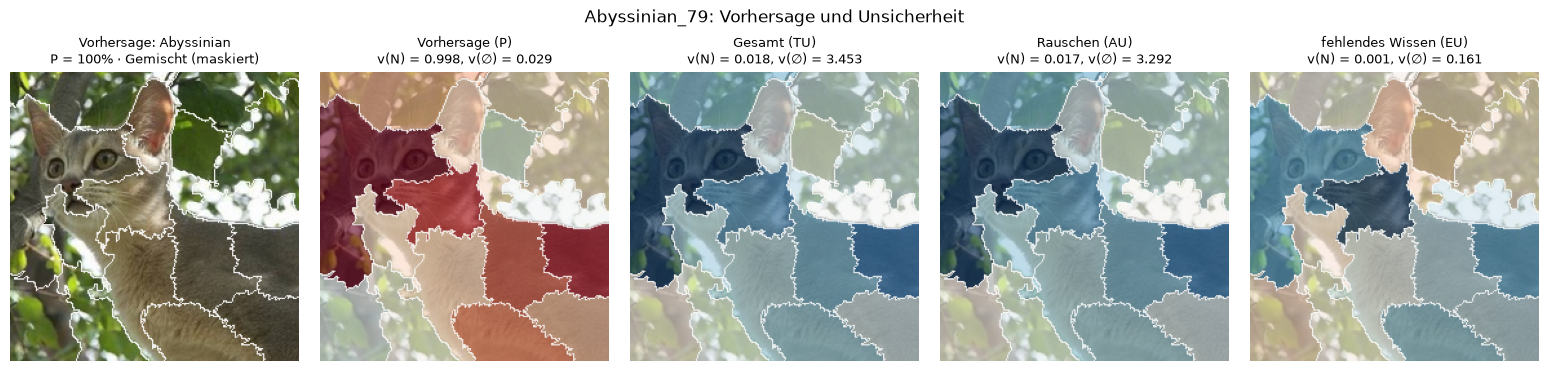

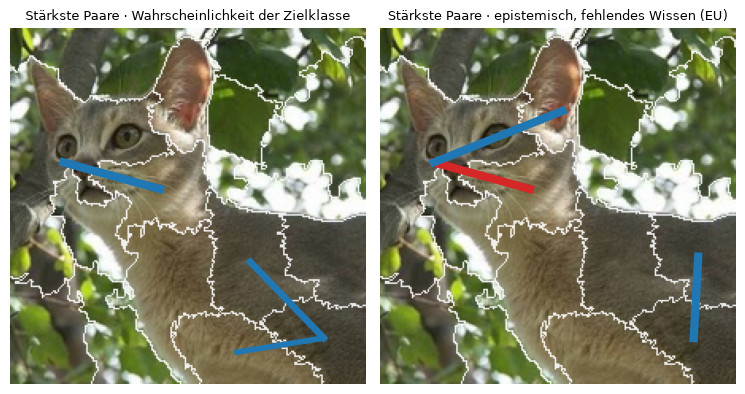

In [3]:
fig = plot_prediction_and_uncertainty(explanation, title=f"{image_id}: Vorhersage und Unsicherheit")
fig.savefig(FIGURES / "beispiel_vorhersage_und_unsicherheit.png", dpi=110)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.8), layout="constrained")
plot_pairs(explanation, "P", ax=axes[0])
plot_pairs(explanation, "EU", ax=axes[1])
plt.show()

**So liest man die Abbildung**

- Jede Karte zeigt den **Shapley-Wert** jedes Superpixels (weiße Linien sind die Grenzen). **Rot** heißt: Dieses
  Superpixel **erhöht** den Wert. **Blau** heißt: Es senkt ihn.
- Unter jedem Titel stehen die beiden Enden des Spiels: v(N) für das ganze Bild und v(∅), wenn alles ausgeblendet
  ist. Die Werte aller Superpixel ergeben zusammen **genau** v(N) − v(∅). Weil das ausgeblendete Bild fast maximal
  unsicher ist (03-0), sind die TU-Werte meist **blau**: Einen Bildteil zu sehen, senkt die Unsicherheit.
- **P** zeigt, welche Bildteile die Vorhersage stützen. **AU** und **EU** zeigen, welche Bildteile das Modell
  unsicher machen, und ob das eher Rauschen oder fehlendes Wissen ist.
- Die zweite Zeile zeigt die stärksten **Paare**: Zwei Superpixel, die **zusammen** anders wirken als einzeln.

## 2. Die ganze Kohorte erklären

Für alle 37 Bilder erklären wir P, TU, AU und EU mit den beiden Ensembles (`Ensemble ViT`, `Gemischt`) in beiden
Kopf-Varianten (normal, maskiert). MC Dropout erklären wir nur auf den 13 Bildern der Teilmenge, weil es Bild für
Bild mit 50 Durchläufen gerechnet wird.

Alle Methoden teilen sich die Transformer-Läufe eines Bildes: Der Cache sorgt dafür, dass jede Koalition nur
einmal durch die Netze geht. Neue Koalitionen werden gespeichert.

In [4]:
def explain(
    image_id: str,
    variant: str,
    method: str,
    *,
    players: str = "slic",
    removal: str = "token",
    fill: str = "blur",
    index: str = settings.INDEX,
    max_order: int = settings.MAX_ORDER,
    budget: int = settings.BUDGET,
) -> UncertaintyExplanation:
    # Explain one image with one probly method; transformer passes come from (and go to) the disk cache.
    cache = coalition_cache(pets, image_id, backbones, players=players, removal=removal, fill=fill)
    ex = UncertaintyExplainer(
        backbones,
        methods[variant][method],
        class_names=pets.classes,
        method_name=f"{method} ({variant})",
        players=players,
        n_players=settings.N_PLAYERS,
        removal=removal,
        fill=fill,
        index=index,
        max_order=max_order,
        budget=budget,
        num_samples=settings.MC_SAMPLES,
        random_state=settings.SEED,
    )
    result = ex.explain(cache.image, regions=cache.regions, coalition_features=cache)
    if result.n_forward:
        save_coalition_cache(cache)
    return result


start, results = time.perf_counter(), {}
for image_id in cohort:
    for variant in ("normal", "maskiert"):
        for method in ("Ensemble ViT", "Gemischt"):
            results[(image_id, variant, method, "slic", "token")] = explain(image_id, variant, method)
    if image_id in subset:
        results[(image_id, "maskiert", "MC Dropout ViT", "slic", "token")] = explain(
            image_id, "maskiert", "MC Dropout ViT"
        )
new = sum(r.n_forward for r in results.values())
print(f"{len(results)} Erklärungen in {time.perf_counter() - start:.0f} s; neue Transformer-Läufe: {new}.")

# Sanity checks on every explanation: efficiency of the Shapley values and phi(TU) = phi(AU) + phi(EU).
# The approximators solve a least-squares problem; their rounding error is about 1e-6 for values around 0.2.
worst = 0.0
for r in results.values():
    for quantity in ("P", "TU", "AU", "EU"):
        assert abs(r.empty[quantity] + r.first_order(quantity).sum() - r.full[quantity]) < 1e-5
    worst = max(
        worst,
        np.abs(r.first_order("TU") - r.first_order("AU") - r.first_order("EU")).max(),
        np.abs(r.pairs("TU") - r.pairs("AU") - r.pairs("EU")).max(),
    )
assert worst < 1e-5
print(
    f"Effizienz und φ(TU) = φ(AU) + φ(EU) gelten für alle Erklärungen (Shapley-Werte und k-SII-Paare); "
    f"größte Abweichung {worst:.1e} (Rundung der Näherung)."
)

161 Erklärungen in 183 s; neue Transformer-Läufe: 0.
Effizienz und φ(TU) = φ(AU) + φ(EU) gelten für alle Erklärungen (Shapley-Werte und k-SII-Paare); größte Abweichung 1.1e-06 (Rundung der Näherung).


## 3. F3: Liegt das fehlende Wissen auf dem Tier oder auf dem Hintergrund?

Oxford-IIIT Pet hat für jedes Bild eine **Trimap**: Tier, Hintergrund und ein schmaler Rand. Wir zählen den Rand
zum Tier. Für jede Karte verteilen wir |φ| eines Superpixels gleichmäßig auf seine Pixel und messen, welcher Anteil
der gesamten Beitragsmasse auf Tier-Pixeln liegt. Davon ziehen wir den **Flächenanteil** des Tiers ab:
0 heißt „so viel, wie die Fläche erwarten lässt“, positiv heißt „überproportional auf dem Tier“.

Zum Vergleich: Dan hat dieselbe Kennzahl mit VGG16, einem 3 × 3-Raster und Weichzeichner berechnet
(Notebook 02-3), zählt den Rand aber getrennt. Bei ihm bekommt der Hintergrund für EU 11,1 Prozentpunkte
weniger Beitragsmasse als seine Fläche. In unserer Zählweise (Tier + Rand) sind das **+11,1 Prozentpunkte**.

**Median über 37 Bilder: Anteil auf dem Tier minus Flächenanteil (Prozentpunkte)**

,P,TU,AU,EU
Gemischt (maskiert),+16.7,+15.0,+15.1,+10.5


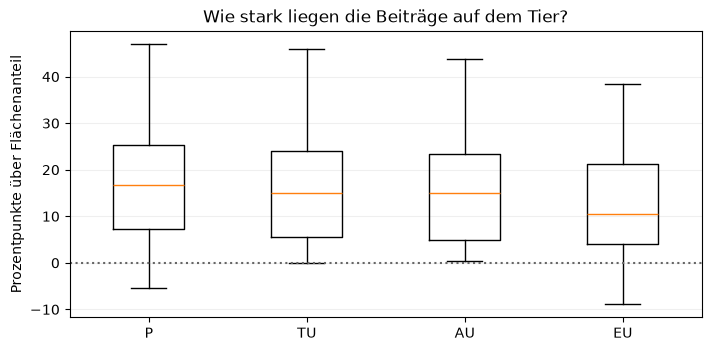

**F3 nach der Regel: gestützt** (Median EU +10.5, P +16.7 Prozentpunkte; EU überproportional auf dem Tier bei 81% der Bilder).

In [5]:
def pet_share(result: UncertaintyExplanation, quantity: str, trimap: np.ndarray) -> float:
    # Share of |phi| mass on pet pixels minus the pet's area share (in percentage points).
    pet = trimap != 2
    magnitude = np.abs(result.first_order(quantity))
    per_pixel = magnitude[result.regions] / np.bincount(result.regions.ravel())[result.regions]
    return 100 * (per_pixel[pet].sum() / per_pixel.sum() - pet.mean())


trimaps = {image_id: pets.load_trimap(image_id) for image_id in cohort}
main = {i: results[(i, *MAIN, "slic", "token")] for i in cohort}  # main configuration, one per image
shares = pd.DataFrame(
    {
        quantity: [pet_share(results[(i, *MAIN, "slic", "token")], quantity, trimaps[i]) for i in cohort]
        for quantity in ("P", "TU", "AU", "EU")
    },
    index=cohort,
)
display(Markdown("**Median über 37 Bilder: Anteil auf dem Tier minus Flächenanteil (Prozentpunkte)**"))
display(shares.median().to_frame("Gemischt (maskiert)").T.style.format("{:+.1f}"))
F3 = shares["EU"].median() > 0
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
ax.boxplot([shares[q] for q in shares], whis=(0, 100))
ax.axhline(0, color="0.4", linestyle=":")
ax.set_xticks(range(1, 5), list(shares))
ax.set(ylabel="Prozentpunkte über Flächenanteil", title="Wie stark liegen die Beiträge auf dem Tier?")
ax.grid(axis="y", alpha=0.2)
fig.savefig(FIGURES / "tier_gegen_hintergrund.png", dpi=110)
plt.show()
display(
    Markdown(
        f"**F3 nach der Regel: {'gestützt' if F3 else 'nicht gestützt'}** "
        f"(Median EU {shares['EU'].median():+.1f}, P {shares['P'].median():+.1f} Prozentpunkte; "
        f"EU überproportional auf dem Tier bei {(shares['EU'] > 0).mean():.0%} der Bilder)."
    )
)

### 3.1 Wie hängen die Karten zusammen?

Rangkorrelation (Spearman) der Shapley-Karten **innerhalb** eines Bildes, Median über 37 Bilder. Ein negativer Wert
zwischen P und EU heißt: Die Bildteile, die die Vorhersage stützen, **senken** das fehlende Wissen.

In [6]:
def rank_corr(a: np.ndarray, b: np.ndarray) -> float:
    return float(spearmanr(a, b).statistic) if np.ptp(a) > 0 and np.ptp(b) > 0 else float("nan")


pairs_of_maps = {"P gegen TU": ("P", "TU"), "P gegen EU": ("P", "EU"), "AU gegen EU": ("AU", "EU")}
map_corr = pd.Series(
    {
        label: np.nanmedian([rank_corr(main[i].first_order(a), main[i].first_order(b)) for i in cohort])
        for label, (a, b) in pairs_of_maps.items()
    }
)
negative = pd.Series(
    {q: np.mean(np.concatenate([main[i].first_order(q) for i in cohort]) < 0) for q in ("P", "TU", "AU", "EU")}
)
display(map_corr.to_frame("Median ρ").T.style.format("{:+.2f}"))
display(Markdown("**Anteil der Superpixel mit negativem Shapley-Wert** (alle 37 × 16 Superpixel)"))
display(negative.to_frame("negativ").T.style.format("{:.0%}"))

,P gegen TU,P gegen EU,AU gegen EU
Median ρ,-0.91,-0.59,+0.51


**Anteil der Superpixel mit negativem Shapley-Wert** (alle 37 × 16 Superpixel)

,P,TU,AU,EU
negativ,18%,90%,91%,55%


## 4. Drei Fälle, nach festen Regeln gewählt

- **Höchste EU** in der Kohorte (gemischtes Ensemble, maskierte Köpfe),
- **Falsch**: das Bild mit der kleinsten Wahrscheinlichkeit für seine wahre Rasse,
- **Sicher**: das Bild mit der kleinsten TU.

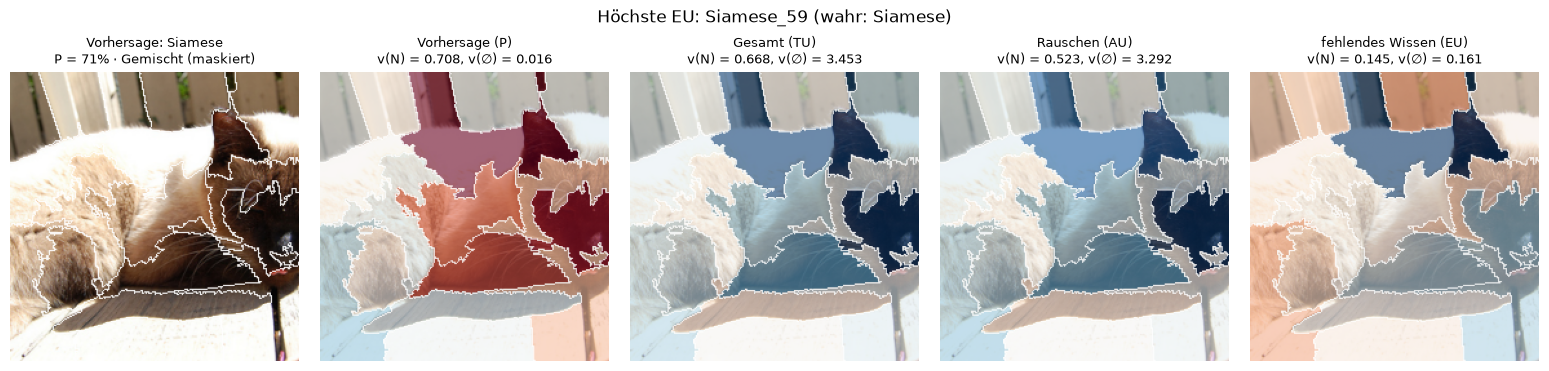

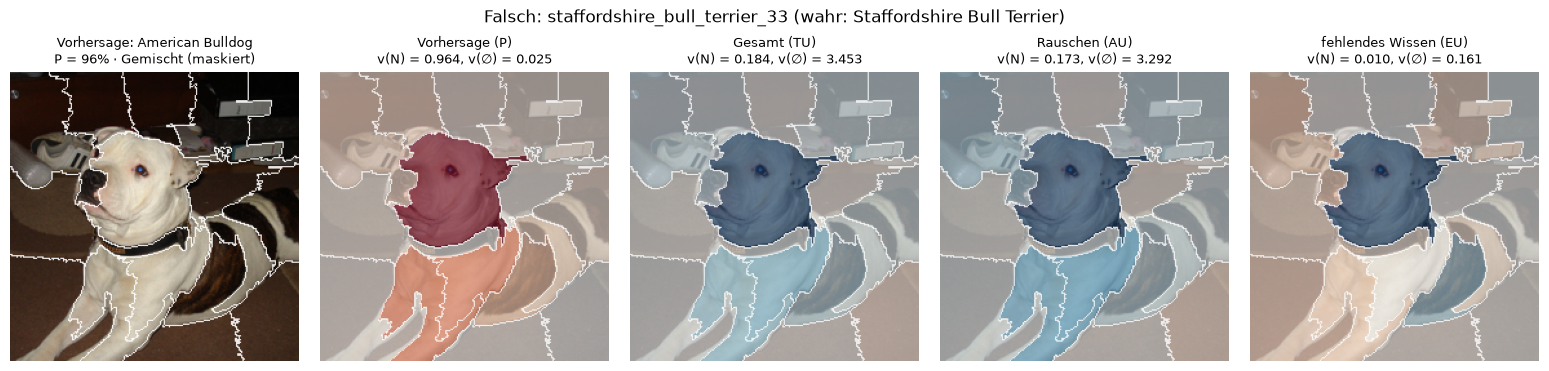

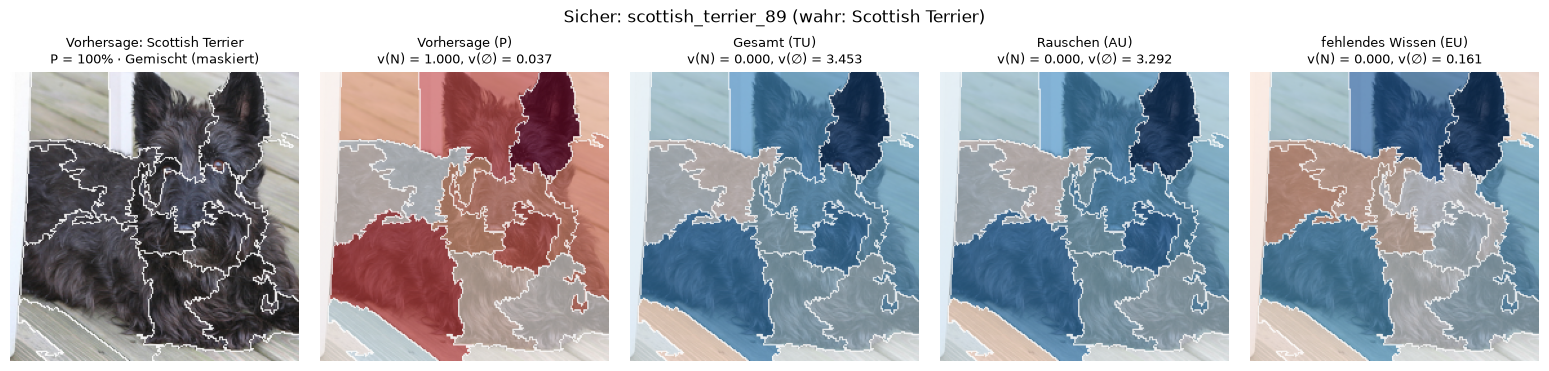

In [7]:
true_prob = {}
for i, label in zip(cohort, cohort_labels, strict=True):
    x = torch.cat([b.features(main[i].image[None]) for b in backbones.values()], dim=1)
    true_prob[i] = uncertainty(methods[MAIN[0]][MAIN[1]], x)["probabilities"][0, label]
cases = {
    "Höchste EU": max(cohort, key=lambda i: main[i].full["EU"]),
    "Falsch": min(cohort, key=lambda i: true_prob[i]),
    "Sicher": min(cohort, key=lambda i: main[i].full["TU"]),
}
for role, image_id in cases.items():
    truth = pets.classes[cohort_labels[cohort.index(image_id)]]
    fig = plot_prediction_and_uncertainty(main[image_id], title=f"{role}: {image_id} (wahr: {truth})")
    # ASCII file name (ö -> oe), safe on every operating system: fall_hoechste.png, fall_falsch.png, ...
    name = role.split()[0].lower().replace("ö", "oe").replace("ä", "ae").replace("ü", "ue")
    fig.savefig(FIGURES / f"fall_{name}.png", dpi=110)
    plt.show()

## 5. F4: SLIC-Superpixel gegen 4 × 4-Raster (wie bei Tom)

Gleiche Methode, gleiches Budget, nur andere Spieler. Ein Raster schneidet das Tier willkürlich; SLIC folgt den
Farbkanten. Regel (vorab): **gestützt**, wenn der Tier-Anteil von P mit SLIC im Median höher ist als mit Raster.

,P slic,P grid,EU slic,EU grid
Median (Prozentpunkte über Fläche),+20.1,+18.6,+16.9,+15.2


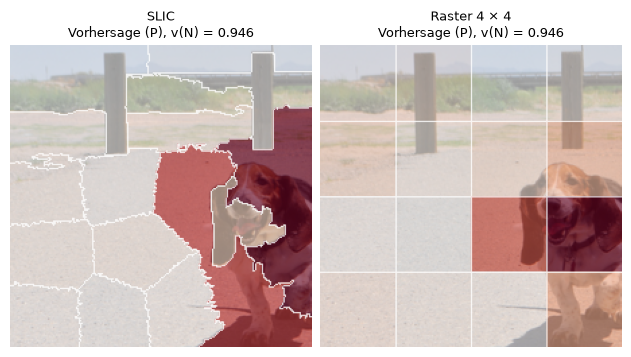

**F4 nach der Regel: gestützt** (Median SLIC − Raster für P: +1.4 Prozentpunkte).

In [8]:
for image_id in subset:
    results[(image_id, *MAIN, "grid", "token")] = explain(image_id, *MAIN, players="grid")
compare = pd.DataFrame(
    {
        f"{quantity} {players}": [
            pet_share(results[(i, *MAIN, players, "token")], quantity, trimaps[i]) for i in subset
        ]
        for quantity in ("P", "EU")
        for players in ("slic", "grid")
    },
    index=subset,
)
difference = compare["P slic"] - compare["P grid"]
F4 = difference.median() > 0
display(compare.median().to_frame("Median (Prozentpunkte über Fläche)").T.style.format("{:+.1f}"))
example = subset[1]
fig = plot_comparison(
    {"SLIC": results[(example, *MAIN, "slic", "token")], "Raster 4 × 4": results[(example, *MAIN, "grid", "token")]},
    "P",
)
plt.show()
display(
    Markdown(
        f"**F4 nach der Regel: {'gestützt' if F4 else 'nicht gestützt'}** "
        f"(Median SLIC − Raster für P: {difference.median():+.1f} Prozentpunkte)."
    )
)

## 6. F5: Weglassen gegen Übermalen

Jetzt entfernen wir Superpixel **im Bild**: Sie werden mit einer weichgezeichneten Kopie übermalt (`blur`, wie in
`shapiq_games`), und das Netz sieht das übermalte Bild vollständig. So müsste man es bei einem CNN wie Dans VGG16
machen. Wir vergleichen die EU-Karten und den Ausgangspunkt v(∅).

,Median ρ (Weglassen gegen Übermalen),v(∅) Weglassen,v(∅) Übermalen,v(N)
Größe,,,,
P,0.724,0.027,0.495,0.940
TU,0.585,3.453,1.417,0.208
AU,0.494,3.292,1.177,0.180
EU,0.347,0.161,0.240,0.028


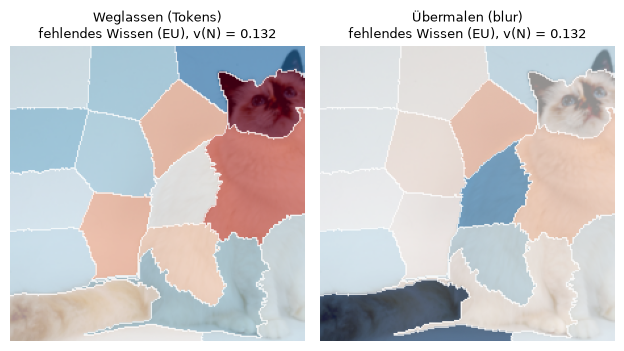

**F5 nach der Regel: gestützt** (Median ρ EU = +0.35).

In [9]:
for image_id in subset:
    results[(image_id, *MAIN, "slic", "fill")] = explain(image_id, *MAIN, removal="fill", fill="blur")

rows = []
for quantity in ("P", "TU", "AU", "EU"):
    token = [results[(i, *MAIN, "slic", "token")] for i in subset]
    fill = [results[(i, *MAIN, "slic", "fill")] for i in subset]
    rows.append(
        {
            "Größe": quantity,
            "Median ρ (Weglassen gegen Übermalen)": np.nanmedian(
                [rank_corr(a.first_order(quantity), b.first_order(quantity)) for a, b in zip(token, fill, strict=True)]
            ),
            "v(∅) Weglassen": np.mean([a.empty[quantity] for a in token]),
            "v(∅) Übermalen": np.mean([b.empty[quantity] for b in fill]),
            "v(N)": np.mean([a.full[quantity] for a in token]),
        }
    )
removal_table = pd.DataFrame(rows).set_index("Größe")
display(removal_table.style.format("{:.3f}"))
F5 = removal_table.loc["EU", "Median ρ (Weglassen gegen Übermalen)"] < 0.5
example = subset[2]
fig = plot_comparison(
    {
        "Weglassen (Tokens)": results[(example, *MAIN, "slic", "token")],
        "Übermalen (blur)": results[(example, *MAIN, "slic", "fill")],
    },
    "EU",
)
fig.savefig(FIGURES / "weglassen_gegen_uebermalen.png", dpi=110)
plt.show()
display(
    Markdown(
        f"**F5 nach der Regel: {'gestützt' if F5 else 'nicht gestützt'}** "
        f"(Median ρ EU = {removal_table.loc['EU', 'Median ρ (Weglassen gegen Übermalen)']:+.2f})."
    )
)

## 7. F6 und die Methoden im Vergleich

- **F6:** Gleiche Methode (`Gemischt`), aber Köpfe normal gegen maskiert trainiert. Ändert sich die EU-Karte?
- **Methoden:** Wie groß sind die EU-Karten von `Ensemble ViT`, `MC Dropout ViT` und `Gemischt`, und zeigen sie
  auf dieselben Superpixel? Größe einer Karte: Σ|φ| über alle Superpixel (in nats).

**Median Σ|φ_EU| je Methode (13 Bilder, maskierte Köpfe)**

,Ensemble ViT,MC Dropout ViT,Gemischt
Σ|φ_EU|,0.0979,0.5468,0.3259


**Median der Rangkorrelation der EU-Karten**

,Ensemble ViT gegen Gemischt,MC Dropout ViT gegen Gemischt,Ensemble ViT gegen MC Dropout ViT
Median ρ,+0.62,+0.53,+0.87


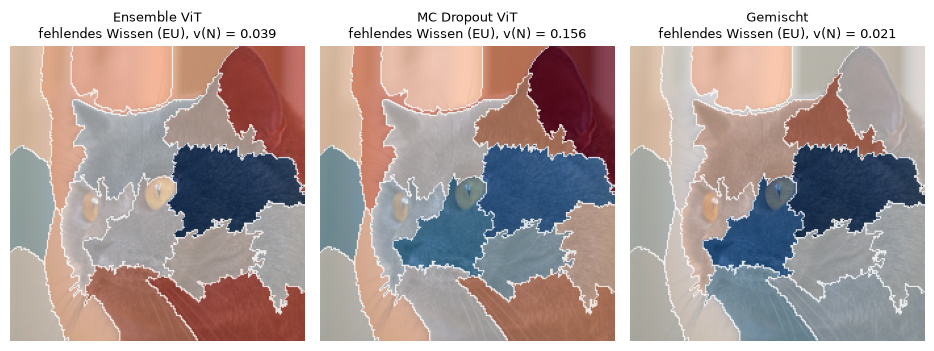

**F6 nach der Regel: nicht gestützt** (Median ρ normal gegen maskiert = +0.71).

In [10]:
f6 = [
    rank_corr(
        results[(i, "normal", "Gemischt", "slic", "token")].first_order("EU"),
        results[(i, "maskiert", "Gemischt", "slic", "token")].first_order("EU"),
    )
    for i in cohort
]
F6 = np.nanmedian(f6) < 0.5
size = pd.DataFrame(
    {
        method: [np.abs(results[(i, "maskiert", method, "slic", "token")].first_order("EU")).sum() for i in subset]
        for method in ("Ensemble ViT", "MC Dropout ViT", "Gemischt")
    },
    index=subset,
)
agreement = {
    f"{a} gegen {b}": np.nanmedian(
        [
            rank_corr(
                results[(i, "maskiert", a, "slic", "token")].first_order("EU"),
                results[(i, "maskiert", b, "slic", "token")].first_order("EU"),
            )
            for i in subset
        ]
    )
    for a, b in (("Ensemble ViT", "Gemischt"), ("MC Dropout ViT", "Gemischt"), ("Ensemble ViT", "MC Dropout ViT"))
}
display(Markdown("**Median Σ|φ_EU| je Methode (13 Bilder, maskierte Köpfe)**"))
display(size.median().to_frame("Σ|φ_EU|").T.style.format("{:.4f}"))
display(Markdown("**Median der Rangkorrelation der EU-Karten**"))
display(pd.Series(agreement).to_frame("Median ρ").T.style.format("{:+.2f}"))
example = subset[3]
fig = plot_comparison(
    {m: results[(example, "maskiert", m, "slic", "token")] for m in ("Ensemble ViT", "MC Dropout ViT", "Gemischt")},
    "EU",
)
fig.savefig(FIGURES / "methoden_eu.png", dpi=110)
plt.show()
display(
    Markdown(
        f"**F6 nach der Regel: {'gestützt' if F6 else 'nicht gestützt'}** "
        f"(Median ρ normal gegen maskiert = {np.nanmedian(f6):+.2f})."
    )
)

## 8. Sind Unsicherheiten stärker eine Sache von Kombinationen?

Verhältnis Σ|Paar-Interaktionen| / Σ|Haupteffekte| von k-SII je Größe (Median über 37 Bilder, Hauptkonfiguration).

In [11]:
ratio = pd.Series(
    {
        quantity: np.median(
            [
                np.abs(np.triu(main[i].pairs(quantity), 1)).sum() / np.abs(main[i].main_effects(quantity)).sum()
                for i in cohort
            ]
        )
        for quantity in ("P", "TU", "AU", "EU")
    }
)
display(ratio.to_frame("Median Σ|Paare| / Σ|Einzelne|").T.style.format("{:.2f}"))

,P,TU,AU,EU
Median Σ|Paare| / Σ|Einzelne|,1.47,1.31,1.37,3.02


## 9. Ergebnis und was wir daraus lernen

In [12]:
verdicts = pd.DataFrame(
    {
        "Frage": [
            "F3 EU liegt auf dem Tier",
            "F4 SLIC lenkt P stärker auf das Tier",
            "F5 Übermalen ändert die EU-Karte",
            "F6 maskiertes Training ändert die EU-Karte",
        ],
        "Kennzahl": [
            f"Median {shares['EU'].median():+.1f} Prozentpunkte",
            f"Median {difference.median():+.1f} Prozentpunkte",
            f"Median ρ = {removal_table.loc['EU', 'Median ρ (Weglassen gegen Übermalen)']:+.2f}",
            f"Median ρ = {np.nanmedian(f6):+.2f}",
        ],
        "Ergebnis": ["gestützt" if v else "nicht gestützt" for v in (F3, F4, F5, F6)],
    }
).set_index("Frage")
display(verdicts)

,Kennzahl,Ergebnis
Frage,,
F3 EU liegt auf dem Tier,Median +10.5 Prozentpunkte,gestützt
F4 SLIC lenkt P stärker auf das Tier,Median +1.4 Prozentpunkte,gestützt
F5 Übermalen ändert die EU-Karte,Median ρ = +0.35,gestützt
F6 maskiertes Training ändert die EU-Karte,Median ρ = +0.71,nicht gestützt


**Was die Ergebnisse in einfachen Worten sagen** (Zahlen aus unserem Lauf, siehe Tabellen oben)

1. **Der Explainer funktioniert mit jeder probly-Methode.** 161 Erklärungen (Ensemble, MC Dropout und gemischtes
   Ensemble; normale und maskierte Köpfe; Superpixel und Raster; Weglassen und Übermalen) liefen ohne einen einzigen
   neuen Transformer-Lauf aus dem Cache. Effizienz und φ(TU) = φ(AU) + φ(EU) gelten überall (größte Abweichung 1,1·10⁻⁶).
2. **Das Tier zu sehen, senkt die Unsicherheit.** 90 % der Shapley-Werte für TU und 91 % für AU sind negativ. Die
   Karten für P und TU sind fast spiegelbildlich (ρ = −0,91): Ein Bildteil, der die Vorhersage stützt, senkt die
   Unsicherheit.
3. **F3 ist gestützt.** Die EU liegt im Median 10,5 Prozentpunkte überproportional auf dem Tier (bei 81 % der Bilder),
   aber weniger stark als P (+16,7) und TU (+15,0). EU ist uneinheitlicher: Nur 55 % ihrer Werte sind negativ. Fast
   jeder zweite Bildteil **erhöht** also das fehlende Wissen. Bildteile, die die Vorhersage stützen, senken es eher
   (ρ = −0,59 zwischen P- und EU-Karte). Dans VGG16-Reihe kam mit einem 3 × 3-Raster und Weichzeichner auf fast
   denselben Wert (+11,1 Prozentpunkte in unserer Zählweise). Modell, Spieler und Entfernung sind dort andere; die
   Übereinstimmung ist ein Hinweis, kein Beweis.
4. **Der Fall „Falsch“ ist die wichtigste Abbildung für die Präsentation.** Ein Staffordshire Bull Terrier wird mit
   96 % als American Bulldog vorhergesagt, bei einer TU von 0,18 und einer EU von nur 0,010 nats. Das Gesicht stützt die
   falsche Vorhersage und senkt gleichzeitig die Unsicherheit. Das Modell ist sich einig, sicher und falsch. Eine
   Erklärung der Unsicherheit deckt so einen Fehler nicht auf; sie zeigt nur, woher die (kleine) Unsicherheit kommt.
5. **F4 (SLIC gegen Raster) ist nach der Regel gestützt, aber der Effekt ist klein.** Auf den 13 Vergleichsbildern
   liegt P mit SLIC im Median 1,4 Prozentpunkte stärker auf dem Tier als mit dem 4 × 4-Raster (Mediane: 20,1 und 18,6
   über dem Flächenanteil). Beide legen die Vorhersage klar auf das Tier. Der Vorteil von SLIC ist vor allem die
   Lesbarkeit: Die Grenzen der Spieler folgen dem Tier.
6. **F5 (Weglassen gegen Übermalen) ist gestützt, und der Grund ist wichtig:** Der Weichzeichner entfernt die
   Information nicht. Ist „alles“ übermalt, gibt das Modell der vorhergesagten Rasse im Mittel noch 50 % (Weglassen:
   3 %), und TU(∅) liegt bei 1,42 statt 3,45 nats. Die EU-Karten unterscheiden sich stark (ρ = 0,35), die P-Karten
   weniger (0,72). Im Vorversuch mit Hautbildern war das Muster dasselbe (ρ = 0,38 für EU,
   0,58 für P). Zwei Datensätze, zwei Modellfamilien, dasselbe Ergebnis: **Erklärungen der Unsicherheit reagieren
   stärker auf die Entfernungsmethode als Erklärungen der Vorhersage.**
7. **F6 ist nicht gestützt** (ρ = 0,71). Ob die Köpfe ausgeblendete Bilder kennen, ändert die Größe der Werte (03-0),
   aber kaum, welche Bildteile wichtig sind.
8. **Methoden im Vergleich:** MC Dropout liefert die größten EU-Karten (Σ|φ| = 0,55), das gemischte Ensemble 0,33, das
   ViT-Ensemble 0,10. Die beiden Methoden auf demselben ViT zeigen auf dieselben Bildteile (ρ = 0,87). Das gemischte
   Ensemble zeigt teilweise woanders hin (ρ = 0,53 bis 0,62), vermutlich weil DINOv2 seine eigene Sicht mitbringt.
   **Wo** fehlendes Wissen liegt, hängt also davon ab, welche Netze man fragt (wie im Vorversuch).
9. **Kombinationen:** Bei EU ist die Summe der Paar-Beiträge im Median dreimal so groß wie die der Einzelbeiträge
   (3,02), bei P nur 1,47. Kombinationen von Bildteilen spielen für fehlendes Wissen also eine viel größere Rolle als
   für die Vorhersage. Das passt zu Bley et al. (2024), nach denen Unsicherheit vor allem aus Effekten zweiter Ordnung
   entsteht. Eine mögliche Erklärung: 73 % der
   EU des gemischten Ensembles entstehen zwischen ViT und DINOv2 (03-0). Ob sich die beiden Netze uneinig sind, hängt
   davon ab, welche Teile des Tiers sie **zusammen** sehen.

**Was das für die Leitfrage bedeutet**

- **Welche Bildteile machen das Modell unsicher?** Fehlt das Tier, bleibt die Unsicherheit hoch; es zu sehen, senkt sie
  am stärksten (in den Beispielen oft das Gesicht). Fehlendes Wissen liegt weniger stark auf dem Tier als die
  Vorhersage (+10,5 gegenüber +16,7 Prozentpunkten) und hängt stärker an Kombinationen von Bildteilen.
- **Rauschen oder fehlendes Wissen?** Auf vollständigen Bildern überwiegt das Rauschen (Mittel der 13 Vergleichsbilder:
  TU 0,21 nats, davon AU 0,18). Das passt dazu, dass sich manche Rassen sehr ähnlich sehen. EU ist klein, aber anders
  im Bild verteilt.
- **Jede Unsicherheits-Erklärung braucht zwei Angaben:** wie Bildteile entfernt werden und welche Netze im Ensemble sind.

**Was das für unser Projekt bedeutet**

- Zwei Kursziele sind für Bilder umgesetzt: ein **Explainer, der mit jeder probly-Methode funktioniert**
  (`UncertaintyExplainer`), und **Plots, die Vorhersage und Unsicherheit nebeneinander erklären**
  (`plot_prediction_and_uncertainty`).
- Standard bei ViTs: **Tokens weglassen**. Für EU lohnen sich **Interaktionen**; Toms Wahl von k-SII bis Ordnung 2 ist
  damit inhaltlich begründet.
- Abbildungen für die Präsentation: `figures/fall_falsch.png`, `figures/weglassen_gegen_uebermalen.png`,
  `figures/methoden_eu.png`, `figures/tier_gegen_hintergrund.png`.

**Grenzen**

- 37 Bilder (eins je Rasse) und 13 für die teuren Vergleiche; Näherungen mit 1000 von 65.536 Koalitionen.
- Der Tier-Anteil über die Trimaps ist grob (jeder Wert wird gleichmäßig auf sein Superpixel verteilt).
- Die Schwellen der Fragen sind vorher gesetzte Regeln, keine statistischen Tests.
- Vergleiche mit Dan und dem Vorversuch sind nur grob: andere Modelle, Spieler und Entfernungen.